# LCK Match Analysis 2024–2026

**Data:** Oracle's Elixir match data (oracleselixir.com), downloaded October 2026. Every game played by LCK teams in 2024–2026: the LCK, Riot international events (MSI, Worlds, First Stand) and third-party events (KeSPA Cup, EWC, ASI, DCGI).

**Questions**
1. Which teams win the most, overall, by split, and at home vs internationally?
2. How do LCK teams play, and what separates the top teams from the rest?
3. Who are the most impactful players on each team?

**Contents**
1. Data loading and cleaning
2. Win rate analysis
3. Team playing style
4. Player analysis
5. Conclusion


### Libraries Used

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import duckdb
import pyarrow
import matplotlib.pyplot as plt

plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e5e1",
    "axes.axisbelow": True,
})

## Data Loading

## Build the Parquet files

Converts each year's Oracle's Elixir CSV into a cleaned, compressed Parquet file in `my_parquet/`, one file per year (`lck_2015.parquet` … `lck_2026.parquet`).
Original CSVs are not changed.

### Steps (inside `make_parquet(year)`)

**1. Read the CSV**
- `low_memory=False`: pandas checks each whole column before choosing its type (avoids `DtypeWarning`).
- `gameid`, `patch`, `url`, `playerid`, `teamid` are read as **text**: they are labels, not numbers.
  (Read as a number, patch `14.10` would become `14.1`.)

**2. Clean names and types**
- Column names: spaces → underscores (`team kpm` → `team_kpm`).
- `date` → real datetime.
- `teamname`: extra spaces removed, so names match exactly across leagues.
- League `OGN` → `LCK` (the LCK's old name, used in 2015).

**3. Filter**
- `lck_teams` collects every team that played in the LCK. It is created **outside** the function, so it grows year by year and teams that left the league still count.
- Keep **every game** with at least one LCK team (LCK, Worlds, MSI, KeSPA Cup, …), including the opponent's rows.
- Exclude `CK` (Challengers Korea, second division).

**4. Shrink types** (same values, less memory)
- Repeated text (`league`, `side`, `teamname`, `champion`, …) → `category`.
- `float64` → `float32`, `int64` → smallest integer type that fits.

**5. Save**
- `index=False`: don't save pandas' row numbers.
- `compression="zstd"`: smaller files, still fast to read.

### Result
| Year | Games | | Year | Games |
|---|---|---|---|---|
| 2015 | 502 | | 2021 | 595 |
| 2016 | 612 | | 2022 | 563 |
| 2017 | 619 | | 2023 | 566 |
| 2018 | 571 | | 2024 | 642 |
| 2019 | 585 | | 2025 | 761 |
| 2020 | 570 | | 2026 | 704 |

Each game has 12 rows (10 players + 2 teams).

### League codes and event types
| Code | Event | Event type |
|---|---|---|
| `LCK` | League of Legends Champions Korea | domestic |
| `WLDs` | World Championship | riot_international |
| `MSI` | Mid-Season Invitational | riot_international |
| `MSC` | Mid-Season Cup (replaced MSI in 2020) | riot_international |
| `FST` | First Stand | riot_international |
| `KeSPA Cup` | KeSPA Cup | third_party |
| `IEM` | Intel Extreme Masters | third_party |
| `EWC` | Esports World Cup | third_party |
| `ASI` | Asia Invitational | third_party |
| `DCGI` | Demacia Cup Global Invitational | third_party |

- **domestic**: the LCK regular season and playoffs.
- **riot_international**: official Riot events between regions.
- **third_party**: events not run by Riot. Teams sometimes play substitutes or try experimental picks, so these can be excluded when measuring competitive performance.
- Any new code not in this table is tagged **unknown** (`fillna("unknown")`), so new events are easy to spot.

`CK` (Challengers Korea, second division) is excluded when building the files.

### Notes
- When grouping by category columns, use `groupby(..., observed=True)`.
- Columns added in later years (e.g. `void_grubs`, `atakhans`) are empty in older years, not zero.
- To add newer data, download the new CSV and rerun the build and cleaning cells.

In [2]:
import pandas as pd
from pathlib import Path

Path("my_parquet").mkdir(exist_ok=True)

# Event type for each league code (same labels as the cleaning step)
EVENT_TYPE = {
    "LCK": "domestic",
    "WLDs": "riot_international", "MSI": "riot_international", "MSC": "riot_international", "FST": "riot_international",
    "KeSPA Cup": "third_party", "IEM": "third_party", "EWC": "third_party", "ASI": "third_party", "DCGI": "third_party",
}

lck_teams = set()   # outside the function, so it keeps growing across years

def make_parquet(year):
    # 1. Read: IDs and patch as text
    df = pd.read_csv(
        f"{year}_LoL_esports_match_data_from_OraclesElixir.csv",
        low_memory=False,
        dtype={"gameid": str, "patch": str, "url": str, "playerid": str, "teamid": str},
    )

    # 2. Clean names and types
    df.columns = df.columns.str.strip().str.replace(" ", "_")
    df["date"] = pd.to_datetime(df["date"], errors="coerce")
    df["teamname"] = df["teamname"].str.strip()
    df["league"] = df["league"].replace({"OGN": "LCK"})     # 2015: old league name

    # 3. Filter: every game with an LCK team, except Challengers Korea
    lck_teams.update(df.loc[df["league"] == "LCK", "teamname"].dropna())
    keep = df["teamname"].isin(lck_teams) & (df["league"] != "CK")
    games = df.loc[keep, "gameid"].unique()
    df = df[df["gameid"].isin(games)].copy()

    # tag each game's event type (after filtering, so it only runs on the rows we keep)
    df["event_type"] = df["league"].map(EVENT_TYPE).fillna("unknown")

    # 4. Shrink types
    for col in ["league", "split", "side", "position", "teamname", "champion",
                "playername", "patch", "event_type"]:
        df[col] = df[col].astype("category")
    for col in df.select_dtypes("float64").columns:
        df[col] = df[col].astype("float32")
    for col in df.select_dtypes("int64").columns:
        df[col] = pd.to_numeric(df[col], downcast="integer")

    # 5. Save
    df.to_parquet(f"my_parquet/lck_{year}.parquet", index=False, compression="zstd")
    print(year, df.shape, df["gameid"].nunique(), "games |",
          df.drop_duplicates("gameid")["event_type"].value_counts().to_dict())

In [3]:
for year in range(2015, 2027):
    make_parquet(year)

2015 (6024, 166) 502 games | {'domestic': 402, 'riot_international': 50, 'unknown': 32, 'third_party': 18}
2016 (7344, 166) 612 games | {'domestic': 490, 'third_party': 62, 'riot_international': 60}
2017 (7428, 166) 619 games | {'domestic': 510, 'riot_international': 55, 'third_party': 54}
2018 (6852, 166) 571 games | {'domestic': 508, 'riot_international': 44, 'third_party': 19}
2019 (7020, 166) 585 games | {'domestic': 496, 'riot_international': 57, 'third_party': 32}
2020 (6840, 166) 570 games | {'domestic': 483, 'riot_international': 47, 'third_party': 40}
2021 (7140, 166) 595 games | {'domestic': 488, 'riot_international': 84, 'unknown': 20, 'third_party': 3}
2022 (6756, 166) 563 games | {'domestic': 467, 'riot_international': 96}
2023 (6792, 166) 566 games | {'domestic': 488, 'riot_international': 78}
2024 (7704, 166) 642 games | {'domestic': 482, 'riot_international': 99, 'third_party': 61}
2025 (9132, 166) 761 games | {'domestic': 555, 'third_party': 109, 'riot_international': 

In [4]:
# Using data from 2024 to 2026
data = {year: pd.read_parquet(f"my_parquet/lck_{year}.parquet") for year in [2024, 2025, 2026]}

## Why 2024–2026?

The analysis uses LCK data from **2024 to 2026** (2,107 games, including Worlds, MSI and other events LCK teams played). Earlier years are available but were left out on purpose.

### Reasons

**1. Relevance to the current game**
League of Legends changes every season: the map, objectives, items and champions all change. Results from 2015–2023 describe a different version of the game, so mixing them in would blur what matters in today's LCK.

**2. Data quality**
Older data is less complete. Checking 2015 showed, for example:
- dragon counts recorded as 0 in every game,
- a large part of the Spring 2015 split missing (137 games and 8 teams vs 231 games and 10 teams in Summer),
- no pick order recorded.

Recent years have more complete and consistent stats.

**3. Consistent features**
Void Grubs exist in every season from 2024, so objective stats are more comparable across the whole period.

**4. Enough data**
Three seasons still give over 2,000 games, enough for reliable team, player and champion statistics.

### Limitations to keep in mind
| Issue | Effect | How it's handled |
|---|---|---|
| **Atakhan** added in 2025 | Column empty for 2024 | Compare Atakhan stats only for 2025–2026 |
| **Fearless Draft** from 2025 | Champion pick/ban rates change | Analyse champion stats for 2024 and 2025–2026 separately |
| **2026: domestic season finished, international events still running** | 2026 has fewer international games than earlier seasons | Re-download and rebuild when new data is released |
| **Unknown dragon types** in 41 games of 2024 | Dragon type columns incomplete for those games | Exclude rows where `dragons_type_unknown` is filled when analysing dragon types |

## Data Cleaning

In [5]:
data[2024].head(2)

,gameid,datacompleteness,url,league,year,split,playoffs,date,game,patch,...,golddiffat25,xpdiffat25,csdiffat25,killsat25,assistsat25,deathsat25,opp_killsat25,opp_assistsat25,opp_deathsat25,event_type
0,LOLTMNT02_22165,complete,None,LCK,2024,Spring,0,2024-01-17 08:20:00,1,14.01,...,-231.0,-760.0,10.0,0.0,2.0,1.0,1.0,2.0,3.0,domestic
1,LOLTMNT02_22165,complete,None,LCK,2024,Spring,0,2024-01-17 08:20:00,1,14.01,...,963.0,-186.0,21.0,4.0,0.0,1.0,1.0,2.0,1.0,domestic


In [6]:
data[2024]["dragons_(type_unknown)"].unique()

array([nan,  3.,  1.,  0.,  4.,  2.], dtype=float32)

In [7]:
list(data[2024].columns)

['gameid',
 'datacompleteness',
 'url',
 'league',
 'year',
 'split',
 'playoffs',
 'date',
 'game',
 'patch',
 'participantid',
 'side',
 'position',
 'playername',
 'playerid',
 'teamname',
 'teamid',
 'firstPick',
 'champion',
 'ban1',
 'ban2',
 'ban3',
 'ban4',
 'ban5',
 'pick1',
 'pick2',
 'pick3',
 'pick4',
 'pick5',
 'gamelength',
 'result',
 'kills',
 'deaths',
 'assists',
 'teamkills',
 'teamdeaths',
 'doublekills',
 'triplekills',
 'quadrakills',
 'pentakills',
 'firstblood',
 'firstbloodkill',
 'firstbloodassist',
 'firstbloodvictim',
 'team_kpm',
 'ckpm',
 'firstdragon',
 'dragons',
 'opp_dragons',
 'elementaldrakes',
 'opp_elementaldrakes',
 'infernals',
 'mountains',
 'clouds',
 'oceans',
 'chemtechs',
 'hextechs',
 'dragons_(type_unknown)',
 'elders',
 'opp_elders',
 'firstherald',
 'heralds',
 'opp_heralds',
 'void_grubs',
 'opp_void_grubs',
 'firstbaron',
 'barons',
 'opp_barons',
 'atakhans',
 'opp_atakhans',
 'firsttower',
 'towers',
 'opp_towers',
 'firstmidtower',


In [8]:
drop_cols = ["url", "monsterkillsownjungle", "monsterkillsenemyjungle"]   # only filled in 41 games of MSI 2024

EVENT_TYPE = {
    "LCK": "domestic",
    "WLDs": "riot_international", "MSI": "riot_international", "FST": "riot_international",
    "KeSPA Cup": "third_party", "EWC": "third_party", "ASI": "third_party", "DCGI": "third_party",
}

In [9]:
# Cleaning pipeline
def clean_year(df):
    df = df.copy()

    # 1. Column names
    df = df.rename(columns={"dragons_(type_unknown)": "dragons_type_unknown"})
    df = df.drop(columns=drop_cols)

    # 2. League codes and event type
    df["league"] = df["league"].astype(str).replace({"KeSPA": "KeSPA Cup"})   # older years use "KeSPA"
    df["event_type"] = df["league"].map(EVENT_TYPE).fillna("unknown")

    # 3. "@25 min" stats only make sense if the game lasted 25 minutes
    at25 = [c for c in df.columns if c.endswith("at25")]
    df.loc[df["gamelength"] < 25 * 60, at25] = np.nan

    # 4. No baron in the game -> firstbaron = 0 for both teams (same as 2024-2025)
    is_team = df["position"] == "team"
    barons_per_game = df[is_team].groupby("gameid")["barons"].sum()
    no_baron_games = barons_per_game[barons_per_game == 0].index
    df.loc[is_team & df["firstbaron"].isna() & df["gameid"].isin(no_baron_games), "firstbaron"] = 0

    # 5. Restore compact types
    for col in ["league", "event_type"]:
        df[col] = df[col].astype("category")
    return df

### League codes and event types
| Code | Event | Event type |
|---|---|---|
| `LCK` | League of Legends Champions Korea (incl. LCK Cup) | domestic |
| `WLDs` | World Championship | riot_international |
| `MSI` | Mid-Season Invitational | riot_international |
| `FST` | First Stand | riot_international |
| `KeSPA Cup` | KeSPA Cup | third_party |
| `EWC` | Esports World Cup | third_party |
| `ASI` | Asia Invitational | third_party |
| `DCGI` | Demacia Cup Global Invitational | third_party |

- **domestic**: the LCK, including the LCK Cup (split `Cup`, from 2025).
- **riot_international**: official Riot events between regions.
- **third_party**: events not run by Riot. Some include teams from several regions, but teams sometimes field substitutes or test strategies, so these can be excluded when measuring competitive performance.
- Any league code not in this table is tagged **unknown**, so new events are easy to spot.

In [10]:
# Iterate through each year (2024-2026)
Path("my_clean").mkdir(exist_ok=True)

data = {}
for year in [2024, 2025, 2026]:
    raw = pd.read_parquet(f"my_parquet/lck_{year}.parquet")
    data[year] = clean_year(raw)
    data[year].to_parquet(f"my_clean/lck_{year}.parquet", index=False, compression="zstd")

    g = data[year][data[year]["position"] == "team"].drop_duplicates("gameid")
    print(year, data[year].shape, "|", g["event_type"].value_counts().to_dict())

2024 (7704, 163) | {'domestic': 482, 'riot_international': 99, 'third_party': 61}
2025 (9132, 163) | {'domestic': 555, 'third_party': 109, 'riot_international': 97}
2026 (8448, 163) | {'domestic': 502, 'third_party': 141, 'riot_international': 61}


In [11]:
def missing_report(data, rows="team"):
    """% missing per year, for team rows or player rows.
    Columns missing in exactly the same pattern are grouped into one line."""
    pct = {}
    for year, df in data.items():
        part = df[df["position"] == "team"] if rows == "team" else df[df["position"] != "team"]
        pct[year] = part.isna().mean() * 100
    table = pd.DataFrame(pct).round(1)

    not_used = (table == 100).all(axis=1)          # never filled for this row type
    complete = (table == 0).all(axis=1)            # never missing
    gaps = table[~not_used & ~complete]

    def short(cols):
        cols = list(cols)
        return ", ".join(cols[:5]) + (f" ... (+{len(cols) - 5} more)" if len(cols) > 5 else "")

    years = list(data.keys())
    grouped = (
        gaps.reset_index(names="column")
        .groupby(years)["column"]
        .agg(n_cols="size", columns=short)
        .sort_values("n_cols", ascending=False)
        .reset_index()
    )

    print(f"===== {rows.upper()} ROWS =====")
    print(f"Complete columns: {complete.sum()} | never used for {rows} rows: {not_used.sum()} "
          f"| columns with gaps: {len(gaps)}")
    print(f"Never used for {rows} rows (expected): {', '.join(table.index[not_used])}\n")
    return grouped

In [12]:
missing_report(data, "team")

===== TEAM ROWS =====
Complete columns: 54 | never used for team rows: 9 | columns with gaps: 100
Never used for team rows (expected): playername, playerid, champion, firstbloodkill, firstbloodassist, firstbloodvictim, damageshare, earnedgoldshare, total_cs



,2024,2025,2026,n_cols,columns
0,6.4,0.0,0.0,69,"doublekills, triplekills, quadrakills, pentaki..."
1,12.9,4.3,6.8,15,"goldat25, xpat25, csat25, opp_goldat25, opp_xp..."
2,0.0,0.0,1.1,8,"ban1, ban2, ban3, pick1, pick2 ... (+3 more)"
3,100.0,0.1,54.0,2,"atakhans, opp_atakhans"
4,0.0,0.1,0.0,1,teamid
5,0.0,0.1,1.1,1,ban4
6,0.2,0.1,1.1,1,ban5
7,5.9,0.0,0.0,1,firstbaron
8,24.9,27.1,28.7,1,split
9,93.6,100.0,100.0,1,dragons_type_unknown


In [13]:
missing_report(data, "player")

===== PLAYER ROWS =====
Complete columns: 47 | never used for player rows: 36 | columns with gaps: 80
Never used for player rows (expected): pick1, pick2, pick3, pick4, pick5, firstdragon, dragons, opp_dragons, elementaldrakes, opp_elementaldrakes, infernals, mountains, clouds, oceans, chemtechs, hextechs, dragons_type_unknown, elders, opp_elders, firstherald, heralds, opp_heralds, void_grubs, opp_void_grubs, firstbaron, atakhans, opp_atakhans, firsttower, towers, opp_towers, firstmidtower, firsttothreetowers, turretplates, opp_turretplates, gspd, gpr



,2024,2025,2026,n_cols,columns
0,6.4,0.0,0.0,54,"doublekills, triplekills, quadrakills, pentaki..."
1,12.9,4.3,6.8,15,"goldat25, xpat25, csat25, opp_goldat25, opp_xp..."
2,6.4,0.0,54.0,4,"barons, opp_barons, inhibitors, opp_inhibitors"
3,0.0,0.0,1.1,3,"ban1, ban2, ban3"
4,0.0,0.1,0.0,1,teamid
5,0.0,0.1,1.1,1,ban4
6,0.2,0.1,1.1,1,ban5
7,24.9,27.1,28.7,1,split


### Missing values: summary
All remaining gaps are explained and are **left as empty values** (not filled), so they are skipped in averages and counts.

| Missing (2024 / 2025 / 2026) | Columns | Cause |
|---|---|---|
| 6.4 / 0 / 0 | Stats at 10/15/20 min, multikills, dragon types, plates, … | MSI 2024: 41 `partial` games |
| 12.9 / 4.3 / 6.8 | `...at25` | Games that ended before 25 minutes |
| 24.9 / 27.1 / 28.7 | `split` | Only LCK games have a split |
| 100 / 0.1 / 54 | `atakhans` (team rows) | Not in the game in 2024; missing for 380 LCK games in 2026 |
| 6.4 / 0 / 54 | `barons`, `inhibitors` (player rows) | MSI 2024 and 2026 LCK gap: use team rows |
| 0 / 0 / 1.1 | bans and picks | 8 DCGI 2026 games |
| 5.9 / 0 / 0 | `firstbaron` | MSI 2024: baron taken, but by whom unknown |
| 93.6 / 100 / 100 | `dragons_type_unknown` | Only used in MSI 2024 |
| ≤ 0.2 | `ban4`, `ban5`, `teamid` | One or two games |

"Never used" columns are expected: they belong to the other row type (e.g. `champion` on team rows, `towers` on player rows).

Key columns (`gameid`, `date`, `league`, `teamname`, `side`, `result`, `kills`, `deaths`, `gamelength`) have **no missing values**.

### Data Merging and Preparation for Analysis

In [14]:
df = pd.concat(data.values(), ignore_index=True)
for col in ["league", "event_type", "split", "side", "position", "teamname", "champion", "playername", "patch"]:
    df[col] = df[col].astype("category")

In [15]:
for col in ["teamname", "side", "league"]:
    df[col] = df[col].astype(str)

# 1. Is this an LCK team? (any team that played in the LCK in 2024-2026)
LCK_TEAMS = set(df.loc[df["league"] == "LCK", "teamname"])
df["is_lck_team"] = df["teamname"].isin(LCK_TEAMS)

# 2. Opponent: the team on the other side in the same game
opp = df.loc[df["position"] == "team", ["gameid", "side", "teamname"]].copy()
opp["side"] = opp["side"].map({"Blue": "Red", "Red": "Blue"})
opp = opp.rename(columns={"teamname": "opponent"})
df = df.merge(opp, on=["gameid", "side"], how="left")
df["opponent_is_lck"] = df["opponent"].isin(LCK_TEAMS)

for col in ["teamname", "opponent", "side", "league", "split", "position", "event_type", "champion", "playername", "patch"]:
    df[col] = df[col].astype("category")

print(len(LCK_TEAMS), "LCK teams:", sorted(LCK_TEAMS))

10 LCK teams: ['BNK FEARX', 'DN SOOPers', 'Dplus Kia', 'Gen.G', 'HANJIN BRION', 'Hanwha Life Esports', 'KT Rolster', 'Kiwoom DRX', 'Nongshim RedForce', 'T1']


In [16]:
df.to_parquet("my_clean/lck_2024_2026.parquet", index=False, compression="zstd")

# next time:
df = pd.read_parquet("my_clean/lck_2024_2026.parquet")

### Optional: adding 2023

2023 was checked but not used (no Void Grubs, one remake game without a winner, and Liiv SANDBOX not linked to BNK FEARX). To add it later, run this in a code cell:

```python
d23 = clean_year(pd.read_parquet("my_parquet/lck_2023.parquet"))

# 1. Drop remakes: games with no winner
winners = d23[d23["position"] == "team"].groupby("gameid")["result"].sum()
d23 = d23[d23["gameid"].isin(winners[winners == 1].index)]

# 2. Connect Liiv SANDBOX to BNK FEARX (check lineage first)
d23["teamname"] = d23["teamname"].astype(str).replace({"Liiv SANDBOX": "BNK FEARX"})
```


# Data Analysis

In [17]:
# Set up SQL 
con = duckdb.connect()
con.execute("CREATE OR REPLACE VIEW lck AS SELECT * FROM 'my_clean/lck_2024_2026.parquet'")

## Win Rate Analysis

In [18]:
con.sql(""" 
            Select * 
            From lck
            LiMIT 5""").df()

,gameid,datacompleteness,league,year,split,playoffs,date,game,patch,participantid,...,killsat25,assistsat25,deathsat25,opp_killsat25,opp_assistsat25,opp_deathsat25,event_type,is_lck_team,opponent,opponent_is_lck
0,LOLTMNT02_22165,complete,LCK,2024,Spring,0,2024-01-17 08:20:00,1,14.01,1,...,0.0,2.0,1.0,1.0,2.0,3.0,domestic,True,Nongshim RedForce,True
1,LOLTMNT02_22165,complete,LCK,2024,Spring,0,2024-01-17 08:20:00,1,14.01,2,...,4.0,0.0,1.0,1.0,2.0,1.0,domestic,True,Nongshim RedForce,True
2,LOLTMNT02_22165,complete,LCK,2024,Spring,0,2024-01-17 08:20:00,1,14.01,3,...,2.0,3.0,1.0,2.0,1.0,2.0,domestic,True,Nongshim RedForce,True
3,LOLTMNT02_22165,complete,LCK,2024,Spring,0,2024-01-17 08:20:00,1,14.01,4,...,2.0,3.0,2.0,1.0,1.0,1.0,domestic,True,Nongshim RedForce,True
4,LOLTMNT02_22165,complete,LCK,2024,Spring,0,2024-01-17 08:20:00,1,14.01,5,...,0.0,5.0,0.0,0.0,4.0,1.0,domestic,True,Nongshim RedForce,True


### Which team has the highest win rate overall?

In [19]:
con.sql("""
    SELECT teamname,
           COUNT(*)                        AS games,
           CAST(SUM(result) AS INTEGER)    AS wins,
           CAST(COUNT(*) - SUM(result) AS INTEGER) AS losses,
           ROUND(AVG(result) * 100, 1)     AS winrate
    FROM lck
    WHERE position = 'team' AND is_lck_team
    GROUP BY teamname
    ORDER BY winrate DESC
""").df()

,teamname,games,wins,losses,winrate
0,Gen.G,444,323,121,72.7
1,Hanwha Life Esports,456,293,163,64.3
2,T1,533,333,200,62.5
3,Dplus Kia,454,248,206,54.6
4,KT Rolster,363,181,182,49.9
5,BNK FEARX,360,162,198,45.0
6,Nongshim RedForce,341,134,207,39.3
7,Kiwoom DRX,301,108,193,35.9
8,HANJIN BRION,318,113,205,35.5
9,DN SOOPers,311,110,201,35.4


### Observation

**Gen.G stands alone at the top.** Their 72.7% win rate is 8.4 points ahead of second place, the largest gap between neighbouring teams. They were the best LCK team in every season (83.5%, 79.3% and 70.5%), though the margin is shrinking. In the LCK regular season (excluding the Cup and playoffs), their lead grows to 13 points (82.0% vs 69.0%).

**Hanwha Life Esports and T1 form a close second tier** at 64.3% and 62.5%. T1 stands out for volume: 533 games, 77 more than any other team, mainly from 120 games at Worlds and MSI and the most LCK playoff games (81). T1 also has the most wins (333), even with the third-best win rate.

**The middle of the table drops off steadily.** Dplus Kia (54.6%) is the only other team clearly above .500. KT Rolster is almost exactly even at 181–182, and BNK FEARX sits a little below at 45.0%.

**The bottom four are tightly packed.** Nongshim RedForce (39.3%), Kiwoom DRX (35.9%), HANJIN BRION (35.5%) and DN SOOPers (35.4%) are within four points of each other, and the last three are separated by only half a point. They played the fewest games (301–341): none reached a Riot international event, and they played only 0–22 LCK playoff games.

*Win rates count games, not series, and combine all events (LCK, LCK Cup, Riot international and third-party events).*

### Which team has the highest win rate in each split / season?

In [20]:
# Win rate per team, per season and split (regular season only),
# with upper/lower groups for the second half of 2025 and 2026
q = con.sql("""
    WITH lck_games AS (
        SELECT *,
               CASE
                 WHEN year = 2025 AND split = 'Rounds 3-5' THEN
                      CASE WHEN teamname IN ('Gen.G', 'Hanwha Life Esports', 'KT Rolster', 'Nongshim RedForce', 'T1')
                           THEN 'upper' ELSE 'lower' END
                 WHEN year = 2026 AND split = 'Rounds 3-4' THEN
                      CASE WHEN teamname IN ('Gen.G', 'Hanwha Life Esports', 'KT Rolster', 'Dplus Kia', 'T1')
                           THEN 'upper' ELSE 'lower' END
               END AS grp
        FROM lck
        WHERE position = 'team' AND league = 'LCK' AND playoffs = 0
    )
    SELECT teamname,
           year || ' ' || split || COALESCE(' (' || grp || ')', '') AS season_split,
           MIN(date)                   AS start,
           COUNT(*)                    AS games,
           ROUND(AVG(result) * 100, 1) AS winrate
    FROM lck_games
    GROUP BY teamname, year, split, grp
""").df()

# Columns in time order
order = q.groupby("season_split")["start"].min().sort_values().index
winrate = q.pivot(index="teamname", columns="season_split", values="winrate")[order]
games   = q.pivot(index="teamname", columns="season_split", values="games")[order]

# Rows: best to worst by overall regular-season win rate (excluding the Cup)
overall = con.sql("""
    SELECT teamname, AVG(result) AS wr
    FROM lck
    WHERE position = 'team' AND league = 'LCK' AND playoffs = 0 AND split <> 'Cup'
    GROUP BY teamname
""").df().set_index("teamname")["wr"]
team_order = overall.sort_values(ascending=False).index
winrate = winrate.loc[team_order]
games   = games.loc[team_order]

# Show with dashes for "not in this group" and a green-red colour scale
(winrate.style
    .format(precision=1, na_rep="–")
    .background_gradient(cmap="RdYlGn", vmin=0, vmax=100)
    .highlight_null(props="background-color: #f2f2f2; color: #999999"))

season_split,2024 Spring,2024 Summer,2025 Cup,2025 Rounds 1-2,2025 Rounds 3-5 (lower),2025 Rounds 3-5 (upper),2026 Cup,2026 Rounds 1-2,2026 Rounds 3-4 (lower),2026 Rounds 3-4 (upper)
teamname,,,,,,,,,,
Gen.G,87.2,92.1,58.6,87.8,–,79.3,90.9,73.2,–,61.1
Hanwha Life Esports,73.2,73.2,63.6,73.8,–,53.6,35.7,74.4,–,52.4
T1,80.0,56.8,65.0,59.5,–,69.0,60.9,75.0,–,42.1
Dplus Kia,50.0,64.4,57.7,51.0,67.9,–,51.4,57.1,–,57.9
KT Rolster,59.1,47.7,43.8,53.2,–,34.6,35.3,63.4,–,38.1
BNK FEARX,37.2,41.5,23.1,37.0,62.1,–,54.5,35.9,50.0,–
Nongshim RedForce,31.8,32.5,51.6,53.3,–,7.7,38.1,31.7,60.0,–
HANJIN BRION,19.5,19.5,28.6,36.2,48.4,–,31.6,40.0,52.4,–
Kiwoom DRX,25.6,25.0,42.9,33.3,44.1,–,45.5,36.4,31.6,–


### Observations
**1. Gen.G is the strongest team, but its lead is shrinking.**
Gen.G had the best win rate in three of the four fully comparable splits, peaking at 92.1% in 2024 Summer. They also topped the upper group in both 2025 (79.3%) and 2026 (61.1%). But the trend is downward: in 2026 Rounds 1-2 they were narrowly third (73.2%) behind T1 (75.0%) and Hanwha Life (74.4%), and their latest result (61.1%) is their lowest outside the Cup.

**2. The upper group is much harder.**
Teams that reach the upper group often struggle against the top five. Nongshim RedForce won only 7.7% there in 2025 (2 of 26 games), KT Rolster 34.6% (2025) and 38.1% (2026). Even T1 fell to 42.1% in 2026, fourth of five in its group.

**3. T1 is strong but inconsistent between splits.**
T1 drops sharply in the second half of a season: 80.0% → 56.8% in 2024, and 75.0% → 42.1% in 2026.

**4. Dplus Kia rose from the lower to the upper group.**
They dominated the lower group in 2025 (67.9%), then held up well in the upper group in 2026 (57.9%), second only to Gen.G.

**5. HANJIN BRION improved steadily.**
In the fully comparable splits they climbed from 19.5% (both 2024 splits) to 36.2% (2025) and 40.0% (2026). In the lower group they rose from 48.4% to 52.4%.

**6. DN SOOPers collapsed in the first half of each season.**
After 41.9% and 47.7% in 2024, they won only 18.6% in 2025 Rounds 1-2 and 8.1% in 2026 Rounds 1-2 (3 wins in 37 games). Their 55.6% in 2026 Rounds 3-4 came against lower-group opponents only.

**7. Kiwoom DRX stayed near the bottom throughout.**
Their best result in any split is 45.5% (2026 Cup), and they never finished above .500.

**8. LCK Cup results don't match the regular season.**
Hanwha Life won only 35.7% in the 2026 Cup but 74.4% in the following split. Nongshim (51.6%) and BNK FEARX (54.5%) did better in the Cup than in most regular-season splits. The Cup is at the start of the season, uses its own format, and has small, unequal samples (13–35 games), so treat Cup results as a weak signal of a team's strength.

### Win rate of each team: domestic vs international

In [21]:
t = con.sql("""
    SELECT teamname,
           COUNT(*) FILTER (WHERE event_type = 'domestic')                                AS dom_games,
           ROUND(AVG(result) FILTER (WHERE event_type = 'domestic') * 100, 1)             AS dom_wr,
           COUNT(*) FILTER (WHERE event_type = 'riot_international')                      AS intl_games,
           ROUND(AVG(result) FILTER (WHERE event_type = 'riot_international') * 100, 1)   AS intl_wr,
           COUNT(*) FILTER (WHERE event_type = 'riot_international' AND opponent_is_lck)  AS vs_lck_games,
           ROUND(AVG(result) FILTER (WHERE event_type = 'riot_international' AND opponent_is_lck) * 100, 1)     AS vs_lck_wr,
           COUNT(*) FILTER (WHERE event_type = 'riot_international' AND NOT opponent_is_lck) AS vs_other_games,
           ROUND(AVG(result) FILTER (WHERE event_type = 'riot_international' AND NOT opponent_is_lck) * 100, 1) AS vs_other_wr,
           COUNT(*) FILTER (WHERE event_type = 'third_party')                             AS tp_games,
           ROUND(AVG(result) FILTER (WHERE event_type = 'third_party') * 100, 1)          AS tp_wr
    FROM lck
    WHERE position = 'team' AND is_lck_team
    GROUP BY teamname
    ORDER BY dom_wr DESC
""").df()

t["gap"] = (t["intl_wr"] - t["dom_wr"]).round(1)
t

,teamname,dom_games,dom_wr,intl_games,intl_wr,vs_lck_games,vs_lck_wr,vs_other_games,vs_other_wr,tp_games,tp_wr,gap
0,Gen.G,324,77.5,71,64.8,26,53.8,45,71.1,49,53.1,-12.7
1,Hanwha Life Esports,332,64.2,58,65.5,7,28.6,51,70.6,66,63.6,1.3
2,T1,338,61.8,120,65.8,30,50.0,90,71.1,75,60.0,4.0
3,Dplus Kia,362,54.4,14,42.9,5,60.0,9,33.3,78,57.7,-11.5
4,KT Rolster,313,49.2,24,70.8,17,58.8,7,100.0,26,38.5,21.6
5,BNK FEARX,304,43.4,14,35.7,3,0.0,11,45.5,42,59.5,-7.7
6,Nongshim RedForce,287,37.3,0,NaN,0,NaN,0,NaN,54,50.0,NaN
7,Kiwoom DRX,276,34.8,0,NaN,0,NaN,0,NaN,25,48.0,NaN
8,HANJIN BRION,276,33.3,0,NaN,0,NaN,0,NaN,42,50.0,NaN
9,DN SOOPers,266,33.1,0,NaN,0,NaN,0,NaN,45,48.9,NaN


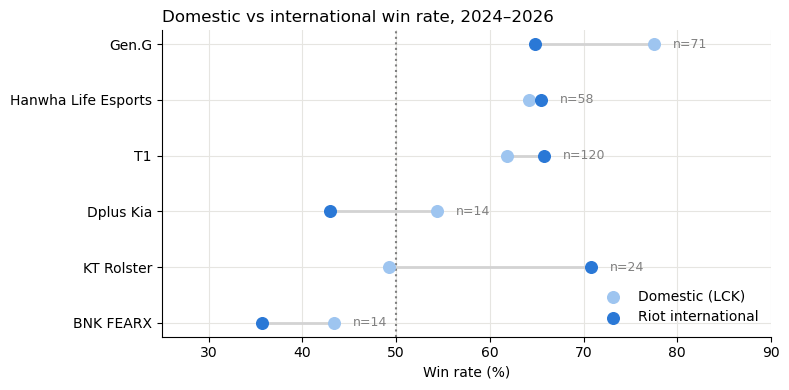

In [22]:
d = t[t["intl_games"] > 0].sort_values("dom_wr")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hlines(d["teamname"], d["dom_wr"], d["intl_wr"], color="lightgray", linewidth=2)
ax.scatter(d["dom_wr"], d["teamname"], color="#9ec5f0", s=70, label="Domestic (LCK)", zorder=3)
ax.scatter(d["intl_wr"], d["teamname"], color="#2a78d6", s=70, label="Riot international", zorder=3)

for _, r in d.iterrows():
    ax.text(max(r.dom_wr, r.intl_wr) + 2, r.teamname, f"n={r.intl_games}", va="center", fontsize=9, color="gray")

ax.axvline(50, color="gray", linestyle=":")
ax.set_xlim(25, 90)
ax.set_xlabel("Win rate (%)")
ax.set_title("Domestic vs international win rate, 2024–2026", loc="left")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

### Why do the gaps happen?


In [23]:
TOP6 = "('Gen.G', 'Hanwha Life Esports', 'T1', 'Dplus Kia', 'KT Rolster', 'BNK FEARX')"

top = con.sql(f"""
    SELECT teamname,
           ROUND(AVG(result) FILTER (WHERE event_type = 'domestic') * 100, 1)                           AS dom_all,
           ROUND(AVG(result) FILTER (WHERE event_type = 'domestic' AND opponent IN {TOP6}) * 100, 1)     AS dom_vs_top6,
           ROUND(AVG(result) FILTER (WHERE event_type = 'domestic' AND opponent NOT IN {TOP6}) * 100, 1) AS dom_vs_bottom4,
           ROUND(AVG(result) FILTER (WHERE event_type = 'riot_international' AND opponent_is_lck) * 100, 1)     AS intl_vs_lck,
           ROUND(AVG(result) FILTER (WHERE event_type = 'riot_international' AND NOT opponent_is_lck) * 100, 1) AS intl_vs_other
    FROM lck
    WHERE position = 'team' AND teamname IN {TOP6}
    GROUP BY teamname
    ORDER BY dom_all DESC
""").df()
# Margin of error of the international win rate, matched by team name
m = t[["teamname", "intl_wr", "intl_games"]].copy()
m["intl_margin"] = (1.96 * np.sqrt((m["intl_wr"] / 100) * (1 - m["intl_wr"] / 100) / m["intl_games"]) * 100).round(1)
top = top.merge(m[["teamname", "intl_margin"]], on="teamname", how="left")
top

,teamname,dom_all,dom_vs_top6,dom_vs_bottom4,intl_vs_lck,intl_vs_other,intl_margin
0,Gen.G,77.5,71.9,93.9,53.8,71.1,11.1
1,Hanwha Life Esports,64.2,54.6,88.3,28.6,70.6,12.2
2,T1,61.8,54.4,83.0,50.0,71.1,8.5
3,Dplus Kia,54.4,42.5,74.6,60.0,33.3,25.9
4,KT Rolster,49.2,39.6,66.7,58.8,100.0,18.2
5,BNK FEARX,43.4,25.7,61.2,0.0,45.5,25.1


**1. Different opponents: the biggest reason.**
A domestic win rate includes many games against the four weakest LCK teams, which the top teams beat easily (Gen.G 93.9%, Hanwha Life 88.3%, T1 83.0%). At Riot events, those teams are absent: LCK opponents there are only the strongest LCK teams, and the other regions' best teams.

| Team | Domestic (all) | Domestic vs top six | Domestic vs bottom four | International vs LCK | International vs other regions |
|---|---|---|---|---|---|
| Gen.G | 77.5% | 71.9% | 93.9% | 53.8% | 71.1% |
| Hanwha Life | 64.2% | 54.6% | 88.3% | 28.6% | 70.6% |
| T1 | 61.8% | 54.4% | 83.0% | 50.0% | 71.1% |
| KT Rolster | 49.2% | 39.6% | 66.7% | 58.8% | 100% |

Compared against similar opponents, most gaps shrink:
- **T1** wins 54.4% against the top six at home and 50.0% against LCK teams abroad, about the same level. Its higher international win rate comes from beating teams from other regions (71.1%), who are on average weaker than the LCK's top six.
- **Gen.G's** drop is partly an opponent effect: its domestic record is boosted by near-perfect results against the bottom four. But even against top-six teams it wins 71.9% at home versus 53.8% against LCK teams abroad, so a real gap remains.

**2. High-stakes series against LCK rivals.**
Gen.G's international losses to LCK teams came mainly in two long series at Worlds: 1–3 against T1 (2024) and 1–3 against KT Rolster (2025). These were best-of-five series (four games each). One series decides a large share of a small sample: those 8 games are almost a third of Gen.G's 26 international games against LCK teams.

**3. Small samples: the extreme gaps are mostly noise.**
KT Rolster's +21.6 points comes from 24 games at two Worlds events, including 3–0 against BNK FEARX (2024) and 3–1 against Gen.G (2025). With so few games, the margin of error is wide:

| Team | International games | Approx. margin of error (95%) |
|---|---|---|
| T1 | 120 | ±8.5 points |
| Gen.G | 71 | ±11 points |
| Hanwha Life | 58 | ±12 points |
| KT Rolster | 24 | ±18 points |
| Dplus Kia, BNK FEARX | 14 | ±25 points |

So KT's strong Worlds results are real, but one or two series either way would change the number a lot. Dplus Kia's and BNK FEARX's gaps are within their margin of error and shouldn't be interpreted.

**Not measured here.** Other factors may play a role but can't be tested with this data: different patches at international events, travel and pressure, and how teams prepare for specific opponents. In this dataset every international game has `playoffs = 0`, so group-stage and knockout games can't be separated directly.

### LCK vs other regions per event

In [24]:
e = con.sql("""
    SELECT year || ' ' || league AS event, MIN(date) AS start, COUNT(*) AS games,
           ROUND(AVG(result) * 100, 1) AS lck_wr
    FROM lck
    WHERE position = 'team' AND is_lck_team AND NOT opponent_is_lck AND event_type = 'riot_international'
    GROUP BY year, league
    ORDER BY start
""").df()
e["event"] = e["event"].str.replace("WLDs", "Worlds").str.replace("FST", "First Stand")
e

,event,start,games,lck_wr
0,2024 MSI,2024-05-01 11:26:50,41,68.3
1,2024 Worlds,2024-10-03 13:31:54,38,60.5
2,2025 First Stand,2025-03-10 11:02:32,17,82.4
3,2025 MSI,2025-07-02 00:13:11,22,68.2
4,2025 Worlds,2025-10-14 08:20:58,34,82.4
5,2026 First Stand,2026-03-16 13:10:29,20,55.0
6,2026 MSI,2026-06-28 03:10:49,41,68.3


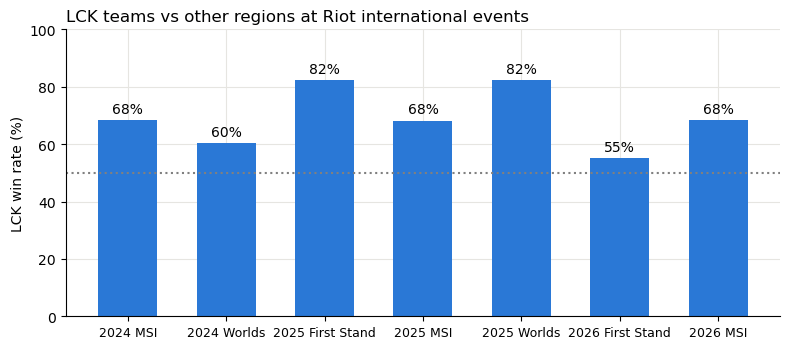

In [25]:
fig, ax = plt.subplots(figsize=(8, 3.6))
bars = ax.bar(e["event"], e["lck_wr"], color="#2a78d6", width=0.6)
ax.bar_label(bars, fmt="%.0f%%", padding=3)
ax.axhline(50, color="gray", linestyle=":")
ax.set_ylim(0, 100)
ax.set_ylabel("LCK win rate (%)")
ax.set_title("LCK teams vs other regions at Riot international events", loc="left")
ax.tick_params(axis="x", labelsize=9)
plt.tight_layout()
plt.show()

### Observation
*Team chart: international = all games at Riot events (MSI, Worlds, First Stand), including 44 LCK vs LCK games. Region chart: LCK vs other regions only, since LCK vs LCK games always split 50/50 for the region.*

**1. The LCK is clearly stronger than other regions.**
LCK teams won 69% of their games against other regions at Riot events (213 games) and finished above 50% at every Riot event in 2024–2026. The region peaked in 2025 (82% at both First Stand and Worlds) and was weakest at First Stand 2026 (55%).

**2. Gen.G is much less dominant internationally.**
Gen.G won 77.5% at home but 64.8% at Riot events (−12.7 points). Against other regions they won 71.1%, but against other LCK teams at international events only 53.8% (26 games), far below their domestic level.

**3. KT Rolster has the strongest international record relative to its domestic form.**
KT won 70.8% at Riot events (24 games), compared with 49.2% at home (+21.6 points). That includes 58.8% against other LCK teams (17 games).

**4. T1 and Hanwha Life perform about the same at home and abroad.**
T1 (61.8% → 65.8%) and Hanwha Life (64.2% → 65.5%) both won about 71% against other regions. T1 split its 30 international games against LCK teams exactly 15–15, while Hanwha Life won only 2 of 7 (28.6%).

**5. Small samples.**
Dplus Kia and BNK FEARX played only 14 international games each, too few to judge. The four lowest-ranked LCK teams never played at a Riot international event, so international results describe the LCK's top teams only.

### Which opponents gave the LCK the most trouble?

In [26]:
s = con.sql("""
    SELECT opponent, COUNT(*) AS games, ROUND(AVG(result) * 100, 1) AS lck_winrate
    FROM lck
    WHERE position = 'team' AND is_lck_team AND NOT opponent_is_lck AND event_type = 'riot_international'
    GROUP BY opponent
    HAVING games >= 8
    ORDER BY lck_winrate
""").df()
s

,opponent,games,lck_winrate
0,Bilibili Gaming,49,51.0
1,Anyone's Legend,17,52.9
2,G2 Esports,28,57.1
3,FlyQuest,12,75.0
4,LYON,8,75.0
5,CTBC Flying Oyster,13,76.9
6,Top Esports,24,79.2
7,Karmine Corp,10,80.0
8,Team Liquid,13,84.6


### Observation

LCK teams beat most teams from other regions comfortably, but three opponents stand out:

- **Bilibili Gaming** (LPL) was the toughest: LCK teams won only **51.0%** of 49 games against them.
- **Anyone's Legend** (LPL) was almost as hard: **52.9%** in 17 games.
- **G2 Esports** (LEC) is next at **57.1%** (28 games).

The two hardest opponents are both from the LPL, so to win international events more often, LCK teams should focus on analysing LPL teams' strategies and how to counter them.

**G2 Esports is one to watch.** They beat Gen.G, the strongest LCK team, **3–0 at First Stand 2026**. Across all their meetings in 2024–2026 the record is even at **5–5** (1–3 at MSI 2025, 1–2 at EWC 2025, 3–0 at First Stand 2026), so G2 has become a real threat to the LCK's best team, although 10 games is still a small sample.


## Team Playing Style Analysis

### How LCK games are played, by season?

In [27]:
con.sql("""
    SELECT year,
           COUNT(*)                                   AS games,
           ROUND(AVG(gamelength) / 60, 1)             AS avg_minutes,
           ROUND(AVG(kills + deaths), 1)              AS kills_per_game,
           ROUND(AVG(ckpm), 2)                        AS kills_per_min,
           ROUND(AVG(dragons + opp_dragons), 2)       AS dragons_per_game,
           ROUND(AVG(void_grubs + opp_void_grubs), 2) AS grubs_per_game,
           ROUND(AVG(barons + opp_barons), 2)         AS barons_per_game,
           ROUND(AVG(CASE WHEN gamelength < 1800 THEN 1 ELSE 0 END) * 100, 1) AS pct_under_30min,
           ROUND(AVG(result) * 100, 1)                AS blue_side_wr
    FROM lck
    WHERE position = 'team' AND league = 'LCK' AND side = 'Blue'
    GROUP BY year
    ORDER BY year
""").df()

,year,games,avg_minutes,kills_per_game,kills_per_min,dragons_per_game,grubs_per_game,barons_per_game,pct_under_30min,blue_side_wr
0,2024,482,32.3,24.6,0.78,4.54,5.38,1.44,38.2,51.5
1,2025,555,32.3,28.8,0.90,4.41,4.24,1.05,38.7,51.0
2,2026,502,32.2,29.4,0.92,4.48,2.88,1.31,38.4,56.4


### Observations
**1. Game length is stable.**
The average game lasted about 32 minutes in all three seasons (32.3 → 32.3 → 32.2), and the share of games under 30 minutes stayed at about 38%. The pace of the game in terms of length has not changed.

**2. But games have become much bloodier.**
Kills per game rose from 24.6 in 2024 to 28.8 in 2025 and 29.4 in 2026, about 20% more. Since game length didn't change, kills per minute rose by the same amount (0.78 → 0.92). Teams fight more often within the same amount of time.

**3. Dragons stay the main objective.**
Dragons per game were almost unchanged (4.54 → 4.41 → 4.48), making them the most consistent objective across the three seasons.

**4. Void Grubs dropped sharply.**
Grubs taken per game nearly halved, from 5.38 (2024) to 4.24 (2025) and 2.88 (2026). A drop this large and steady most likely reflects game changes to the objective rather than teams ignoring it, so grub statistics should be compared within a season, not across seasons.

**5. Fewer barons since 2025.**
Barons per game dropped from 1.44 (2024) to 1.05 (2025), the season Atakhan was added as a new objective, then partly recovered to 1.31 (2026).

**6. Blue side gained an advantage in 2026.**
Blue side won 51.5% (2024) and 51.0% (2025), close to even. In 2026 it won 56.4% of 502 games. With a margin of error of about ±4.3 points, this is likely a real advantage rather than chance, unlike the earlier seasons, where the difference from 50% is within the margin of error.

### Each team's style

In [28]:
style = con.sql("""
    SELECT teamname,
           ROUND(AVG(result) * 100, 1)       AS wr,
           ROUND(AVG(golddiffat15))          AS gd15,
           ROUND(AVG(firstblood) * 100, 1)   AS first_blood,
           ROUND(AVG(firsttower) * 100, 1)   AS first_tower,
           ROUND(AVG(firstdragon) * 100, 1)  AS first_dragon,
           ROUND(SUM(void_grubs) / SUM(void_grubs + opp_void_grubs) * 100, 1) AS grub_share,
           ROUND(SUM(dragons) / SUM(dragons + opp_dragons) * 100, 1)          AS dragon_share,
           ROUND(SUM(barons) / SUM(barons + opp_barons) * 100, 1)             AS baron_share,
           ROUND(AVG(team_kpm), 2)           AS kills_per_min,
           ROUND(AVG(vspm), 2)               AS vision_per_min,
           ROUND(AVG(gamelength) FILTER (WHERE result = 1) / 60, 1) AS min_in_wins,
           ROUND(AVG(gamelength) FILTER (WHERE result = 0) / 60, 1) AS min_in_losses,
           ROUND(AVG(result) FILTER (WHERE golddiffat15 > 0) * 100, 1) AS wr_ahead_15,
           ROUND(AVG(result) FILTER (WHERE golddiffat15 < 0) * 100, 1) AS wr_behind_15
    FROM lck
    WHERE position = 'team' AND league = 'LCK'
    GROUP BY teamname
    ORDER BY wr DESC
""").df()
style

,teamname,wr,gd15,first_blood,first_tower,first_dragon,grub_share,dragon_share,baron_share,kills_per_min,vision_per_min,min_in_wins,min_in_losses,wr_ahead_15,wr_behind_15
0,Gen.G,77.5,916.0,48.1,63.9,56.2,60.3,62.3,66.9,0.53,9.68,31.4,34.1,92.3,54.7
1,Hanwha Life Esports,64.2,614.0,54.8,62.7,48.5,51.8,54.2,59.3,0.50,9.44,31.6,33.0,79.4,36.4
2,T1,61.8,581.0,50.6,59.5,55.3,45.8,52.4,59.1,0.49,9.15,31.8,33.4,77.7,37.1
3,Dplus Kia,54.4,358.0,54.1,49.4,51.4,42.1,50.2,50.1,0.44,9.28,32.4,33.7,69.8,34.4
4,KT Rolster,49.2,-109.0,51.8,49.2,52.7,55.8,52.3,48.5,0.42,9.26,33.3,32.1,72.2,25.8
5,BNK FEARX,43.4,-360.0,49.3,46.4,49.3,51.9,47.6,48.2,0.44,9.03,31.5,31.7,66.2,26.4
6,Nongshim RedForce,37.3,-392.0,49.5,46.0,43.6,52.3,44.4,44.0,0.41,8.76,31.7,31.4,62.4,20.0
7,Kiwoom DRX,34.8,-823.0,46.4,37.0,46.7,49.0,44.7,40.5,0.37,8.81,33.6,31.8,60.2,20.8
8,HANJIN BRION,33.3,-603.0,51.4,39.5,50.0,42.3,42.4,37.9,0.37,8.93,33.7,31.8,57.5,18.2
9,DN SOOPers,33.1,-665.0,41.4,39.8,43.6,48.2,45.0,37.3,0.35,8.82,33.8,31.4,54.1,18.5


In [29]:
style.set_index("teamname").corr()["wr"].drop("wr").sort_values(ascending=False).round(2)

baron_share       0.98
wr_ahead_15       0.98
gd15              0.98
wr_behind_15      0.97
dragon_share      0.96
kills_per_min     0.96
first_tower       0.96
vision_per_min    0.94
min_in_losses     0.91
first_dragon      0.76
grub_share        0.45
first_blood       0.42
min_in_wins      -0.68
Name: wr, dtype: float64

### Observations

**What separates strong and weak teams**
How closely each stat follows win rate across the 10 teams (1 = perfectly, 0 = not at all):

| Strongly linked to winning (0.9+) | Moderately linked | Weakly linked |
|---|---|---|
| Gold lead at 15 (0.98), baron share (0.98), lead conversion (0.98), comebacks (0.97), first tower (0.96), dragon share (0.96), kills per minute (0.96), vision (0.94) | First dragon (0.76) | Void Grub share (0.45), first blood (0.42) |

**1. First blood and Void Grubs don't decide who's good.**
Gen.G, the best team, gets first blood in only 48.1% of games, below average, while HANJIN BRION (33.3% win rate) gets it in 51.4%. Grub share is similar: KT Rolster (55.8%) and Nongshim (52.3%) take more grubs than T1 (45.8%) or Dplus Kia (42.1%, the lowest).

**2. First tower and the gold lead at 15 almost rank the table by themselves.**
The top three teams take first tower in 59–64% of games, the bottom three in 37–40%. Gold difference at 15 minutes goes from +916 (Gen.G) to −823 (Kiwoom DRX), in nearly the same order as win rate.

**3. Gen.G leads in almost everything.**
Gen.G has the highest gold lead at 15 (+916), first tower (63.9%), first dragon (56.2%), and grub (60.3%), dragon (62.3%) and baron share (66.9%), plus the most kills per minute and the best vision. It also converts 92.3% of games where it leads at 15, and wins 54.7% even when behind, the only team that wins most of its games from behind.

**4. Each top team has a different profile.**
- **Hanwha Life**: early aggression. The highest first-blood rate (54.8%) and second-highest first tower (62.7%), but below-average first dragon (48.5%).
- **T1**: dragon side. A high first-dragon rate (55.3%) but a below-average grub share (45.8%), and the second-best comeback rate (37.1%).

**5. Dplus Kia and KT Rolster are mirror images.**
Dplus Kia builds early leads (+358 gold at 15) but converts them less often (69.8%). KT Rolster is usually behind at 15 (−109) but converts leads better (72.2%) and has the second-highest grub share (55.8%).

**6. Weaker teams win late and lose fast.**
The top four teams finish wins faster than losses (e.g. Gen.G: 31.4 vs 34.1 min). For KT, Kiwoom DRX, HANJIN BRION and DN SOOPers it's the reverse: their wins take about 33–34 minutes, their losses about 32. They rarely win from an early lead, so their wins tend to come from longer, later games.

**7. Weaker teams struggle to close games.**
DN SOOPers win only 54.1% of games where they lead at 15, and HANJIN BRION 57.5%, barely better than a coin flip, compared with 92.3% for Gen.G.

*Note: these are correlations across only 10 teams. Some stats are partly a result of winning rather than a cause: a team that is winning takes more barons and gets more kills because it is ahead. First tower and gold at 15 are better signs of style, since they're measured before the game is decided.*

### Top seeds vs the rest

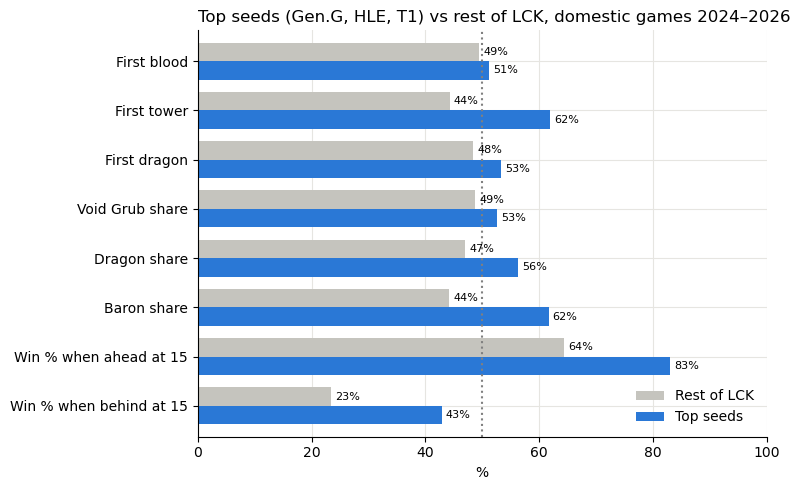

In [30]:
groups = con.sql("""
    SELECT CASE WHEN teamname IN ('Gen.G', 'Hanwha Life Esports', 'T1') THEN 'Top seeds' ELSE 'Rest of LCK' END AS grp,
           AVG(firstblood) * 100                                    AS "First blood",
           AVG(firsttower) * 100                                    AS "First tower",
           AVG(firstdragon) * 100                                   AS "First dragon",
           SUM(void_grubs) / SUM(void_grubs + opp_void_grubs) * 100 AS "Void Grub share",
           SUM(dragons) / SUM(dragons + opp_dragons) * 100          AS "Dragon share",
           SUM(barons) / SUM(barons + opp_barons) * 100             AS "Baron share",
           AVG(result) FILTER (WHERE golddiffat15 > 0) * 100        AS "Win % when ahead at 15",
           AVG(result) FILTER (WHERE golddiffat15 < 0) * 100        AS "Win % when behind at 15"
    FROM lck
    WHERE position = 'team' AND league = 'LCK'
    GROUP BY grp
""").df().set_index("grp").T[["Top seeds", "Rest of LCK"]]

ax = groups.iloc[::-1].plot.barh(figsize=(8, 5), color=["#2a78d6", "#c5c4be"], width=0.75)
for c in ax.containers:
    ax.bar_label(c, fmt="%.0f%%", padding=3, fontsize=8)
ax.axvline(50, color="gray", linestyle=":")
ax.set_xlim(0, 100)
ax.set_xlabel("%")
ax.set_title("Top seeds (Gen.G, HLE, T1) vs rest of LCK, domestic games 2024–2026", loc="left")
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

### Observations

*League-wide trends (game length, kills, objectives, blue side) are in the "How LCK games are played" observations above; team identities are in "Each team's style".*

**1. Structures and big objectives decide games more than early kills.** League-wide, the team that gets first blood wins 55.6% of games, first dragon 60.2%, first tower 67.8%, and first baron 85.2%. A gold lead at 15 minutes wins 71.9% of the time, and a lead over 2,000 gold wins 88.4%.

**2. Top seeds don't win the early fights, they win the map.** First blood is nearly even (51.2% vs 49.4%), but top seeds take first tower 62.0% of the time (vs 44.3%) and lead by 701 gold at 15 minutes (vs −334). Their advantage comes from lanes and structures, not early skirmishes.

**3. They control the big objectives.** Top seeds take 56.3% of dragons and 61.7% of barons, against 47.0% and 44.2% for the rest.

**4. They convert leads and come back from deficits.** When ahead at 15 minutes, top seeds win 83.0% (rest: 64.5%). When behind, they still win 42.9%, almost twice the rest of the league (23.3%). They also finish wins faster (31.6 min) and drag out losses longer (33.4 min).


## Player Analysis

### How players are rated

Each player gets a **score from 1 to 10** based on the statistics that matter for their position:

| Position | Statistics used |
|---|---|
| Top, mid, bot | KDA, damage per minute, damage share, gold lead at 15, CS lead at 15 |
| Jungle | KDA, kill participation, gold lead at 15, XP lead at 15, vision per minute, first-blood participation |
| Support | KDA, kill participation, vision per minute, wards cleared per minute, first-blood participation |

**Method**
1. Domestic LCK games only, so all players face the same opponents.
2. Each player's **most recent games with their current team**, up to 100 (at least 30). Games for earlier teams are not counted.
3. For each statistic, players are compared **only with other players in the same position** (z-score: how far above or below the position average, in standard deviations). The average of these is the rating.
4. Score = 5 + 2.5 × rating, limited to 1–10. **5 = average for the position**, 7.5 = clearly above average, 10 = exceptional.
5. Players are grouped by `playerid`, not name (two different IDs use the name "Taeyoon").

**Limitation:** the score measures statistics, not everything a player contributes. Shotcalling, leadership and utility champions that enable teammates don't show up. For example, Faker scores 2.2 even though T1 won 58% of these games.


In [31]:
RATING = {
    "top": ["kda", "dpm", "dmg_share", "gd15", "csd15"],
    "jng": ["kda", "kp", "gd15", "xpd15", "vspm", "fb_part"],
    "mid": ["kda", "dpm", "dmg_share", "gd15", "csd15"],
    "bot": ["kda", "dpm", "dmg_share", "gd15", "csd15"],
    "sup": ["kda", "kp", "vspm", "wcpm", "fb_part"],
}

In [32]:
last100_team = con.sql("""
    WITH games AS (
        SELECT *,
               arg_max(teamname, date) OVER (PARTITION BY playerid) AS current_team,
               MAX(year)               OVER (PARTITION BY playerid) AS last_season
        FROM lck
        WHERE position <> 'team' AND event_type = 'domestic'
    ),
    ranked AS (
        SELECT *, ROW_NUMBER() OVER (PARTITION BY playerid ORDER BY date DESC) AS game_no
        FROM games
        WHERE teamname = current_team AND last_season = 2026
    )
    SELECT playerid,
           arg_max(playername, date)                                  AS player,
           current_team                                               AS team,
           arg_max(position, date)                                    AS position,
           COUNT(*)                                                   AS games,
           MIN(date)::DATE                                            AS from_date,
           ROUND(AVG(result) * 100, 1)                                AS wr,
           ROUND((SUM(kills) + SUM(assists)) / GREATEST(SUM(deaths), 1), 2) AS kda,
           ROUND((SUM(kills) + SUM(assists)) / SUM(teamkills) * 100, 1)     AS kp,
           ROUND(AVG(dpm))                                            AS dpm,
           ROUND(AVG(damageshare) * 100, 1)                           AS dmg_share,
           ROUND(AVG(golddiffat15))                                   AS gd15,
           ROUND(AVG(csdiffat15), 1)                                  AS csd15,
           ROUND(AVG(xpdiffat15))                                     AS xpd15,
           ROUND(AVG(vspm), 2)                                        AS vspm,
           ROUND(AVG(wcpm), 2)                                        AS wcpm,
           ROUND(AVG(firstbloodkill + firstbloodassist) * 100, 1)     AS fb_part
    FROM ranked
    WHERE game_no <= 100
    GROUP BY playerid, current_team
    HAVING COUNT(*) >= 30
""").df()

for pos, stats in RATING.items():
    rows = last100_team["position"] == pos
    z = (last100_team.loc[rows, stats] - last100_team.loc[rows, stats].mean()) / last100_team.loc[rows, stats].std()
    last100_team.loc[rows, "rating"] = z.mean(axis=1)
last100_team["score"] = (5 + 2.5 * last100_team["rating"]).clip(1, 10).round(1)

best_per_team = last100_team.sort_values("score", ascending=False).groupby("team").head(1)
best_per_team[["team", "player", "position", "games", "from_date", "wr", "score", "kda", "dmg_share", "gd15", "csd15", "vspm"]]

,team,player,position,games,from_date,wr,score,kda,dmg_share,gd15,csd15,vspm
5,Gen.G,Chovy,mid,100,2026-01-15,75.0,9.8,5.85,25.8,314.0,10.4,1.56
26,T1,Peyz,bot,100,2026-01-25,58.0,8.0,4.46,29.2,501.0,5.0,1.31
48,KT Rolster,Effort,sup,85,2026-04-01,51.8,6.9,3.60,7.7,36.0,0.2,4.47
35,Hanwha Life Esports,Delight,sup,100,2025-09-20,59.0,6.9,4.05,7.1,133.0,5.0,4.33
0,DN SOOPers,DuDu,top,100,2025-08-15,33.0,6.9,2.26,24.7,160.0,5.4,1.32
11,Nongshim RedForce,Scout,mid,86,2026-01-15,39.5,6.6,3.41,25.1,161.0,2.4,1.22
51,Dplus Kia,Lucid,jng,100,2026-02-13,54.0,6.4,3.21,17.1,57.0,5.2,1.95
21,HANJIN BRION,Teddy,bot,93,2026-01-14,39.8,5.6,3.48,28.9,31.0,1.0,1.17
36,BNK FEARX,Taeyoon,bot,59,2026-05-03,49.2,5.4,3.65,27.6,-67.0,5.9,1.71
23,Kiwoom DRX,Rich,top,100,2025-08-02,41.0,4.8,2.69,23.6,-188.0,-6.5,1.45


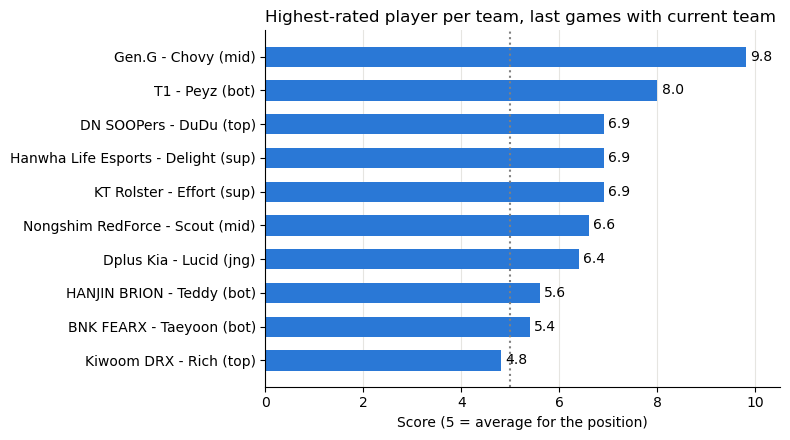

In [33]:
b = best_per_team.sort_values("score")
labels = b["team"] + " - " + b["player"] + " (" + b["position"] + ")"

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.barh(labels, b["score"], color="#2a78d6", height=0.6)
ax.bar_label(bars, fmt="%.1f", padding=3)
ax.axvline(5, color="gray", linestyle=":")
ax.set_xlim(0, 10.5)
ax.set_xlabel("Score (5 = average for the position)")
ax.set_title("Highest-rated player per team, last games with current team", loc="left")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

### Highest-rated player per team (most recent games with current team, up to 100)
*Score: 5 = average for the position, 10 = exceptional. Only games for the player's current team count.*

- **Gen.G and T1 are led by clear stars.** Chovy (9.8) and Peyz (8.0) are the only players above 8. Gen.G's whole roster scores 6.6 or higher; on T1, Peyz is the only player above 5.5.
- **Hanwha Life's strength is spread out.** Delight (6.9), Zeka (6.7), Zeus (6.6) and Kanavi (6.2) are close together, so the team doesn't depend on one player.
- **Supports lead two teams.** Delight (Hanwha Life) and Effort (KT) are their teams' highest-rated players, through vision and kill participation.
- **Strong individuals on weak teams.** DuDu (6.9, DN SOOPers, 33% win rate) and Scout (6.6, Nongshim, 39.5%) rate well above average on struggling teams.
- **Kiwoom DRX has no player above average.** Its best player, Rich, scores 4.8, and the team's two bot laners score 1.6 or lower.

## Conclusion

**1. Gen.G is the strongest LCK team of 2024–2026.** 72.7% of all games won, the best LCK record in every season, and the most top-rated players (Chovy, Kiin, Duro, Ruler, Canyon all score 6.6 or higher). But their lead is shrinking, and internationally they win only 53.8% against other LCK teams.

**2. The LCK is the strongest region.** LCK teams won 69% of games against other regions at Riot events and finished above 50% at every event. The toughest opponents were LPL teams (Bilibili Gaming, Anyone's Legend) and G2 Esports.

**3. Strong teams win the map, not the first fight.** First tower, gold lead at 15 and objective control follow win rate almost perfectly; first blood and Void Grubs barely matter. Top teams also convert leads (83%) and come back from deficits (43%) far more often than the rest.

**4. The game is getting bloodier.** Games still last about 32 minutes, but kills per game rose about 20% from 2024 to 2026, and blue side gained an advantage in 2026 (56.4%).

**5. Chovy is the best player in the data.** His score is 9.8/10 over his last 100 games, the highest in the league, with Peyz (T1, 8.0) second.

### Limitations
- Win rates count games, not series.
- The player score measures statistics, not shotcalling, leadership or utility play.
- Some results rest on small samples (international games for most teams, recent stints of transferred players).
- The data covers 2024–2026 only.
